<h1 align ='center' style='color:white'>Credit Risk Modelling Project</h1>

<h3 align ='center' style='color:yellow'>Data Collection and Cleaning</h3>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import average
from sklearn.model_selection import train_test_split

pd.set_option('display.float_format', lambda x: '{:.2f}'.format(x))
np.set_printoptions(suppress=True)

In [5]:
df_customers = pd.read_csv('customers.csv')
df_loans = pd.read_csv('loans.csv')
df_bureau = pd.read_csv('bureau_data.csv')

In [6]:
df_customers.shape, df_loans.shape, df_bureau.shape

((50000, 12), (50000, 15), (50000, 8))

In [7]:
df = pd.merge(df_customers, df_loans, on='cust_id')
df.head()

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2467000,49340.00,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,3883000,77660.00,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,...,2170000,43400.00,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False
3,C00004,55,F,Single,Self-Employed,3547000,1,Owned,15,Bangalore,...,1747000,34940.00,314460,1397600,6,1257839,1031094,2019-07-24,2019-08-09,False
4,C00005,37,M,Married,Salaried,3432000,3,Owned,28,Pune,...,4520000,90400.00,813600,3616000,28,1772334,1032458,2019-07-24,2019-08-02,False


In [8]:
df = pd.merge(df, df_bureau)
df.head()

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2019-07-24,2019-08-10,False,1,1,42,0,0,3,7
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,2019-07-24,2019-08-15,False,3,1,96,12,60,5,4
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,...,2019-07-24,2019-08-21,False,2,1,82,24,147,6,58
3,C00004,55,F,Single,Self-Employed,3547000,1,Owned,15,Bangalore,...,2019-07-24,2019-08-09,False,3,0,115,15,87,5,26
4,C00005,37,M,Married,Salaried,3432000,3,Owned,28,Pune,...,2019-07-24,2019-08-02,False,4,2,120,0,0,5,10


In [9]:
df['default'] = df['default'].astype(int)
df.default.value_counts()

,count
default,
0,45703
1,4297


In [10]:
X = df.drop('default', axis=1)
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

In [11]:
df_train = pd.concat([X_train, y_train], axis=1)
df_test = pd.concat([X_test, y_test], axis=1)

df_train.head()

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
12746,C12747,59,M,Married,Self-Employed,11327000,3,Owned,30,Hyderabad,...,2020-10-31,2020-11-11,4,2,152,20,118,4,36,0
32495,C32496,44,F,Single,Salaried,715000,0,Owned,27,Mumbai,...,2022-10-22,2022-10-27,3,1,160,10,62,5,5,0
43675,C43676,38,M,Single,Salaried,3195000,0,Mortgage,26,Chennai,...,2023-12-04,2023-12-29,1,1,54,12,67,4,0,0
9040,C09041,42,M,Married,Salaried,1500000,2,Mortgage,30,Bangalore,...,2020-06-18,2020-07-07,3,0,76,0,0,8,87,0
13077,C13078,58,M,Married,Self-Employed,1817000,4,Owned,29,Pune,...,2020-11-12,2020-12-07,1,2,60,0,0,1,71,0


In [12]:
df_train.isna().sum()

,0
cust_id,0
age,0
gender,0
marital_status,0
employment_status,0
income,0
number_of_dependants,0
residence_type,47
years_at_current_address,0
city,0


In [13]:
df_train.residence_type.unique()

array(['Owned', 'Mortgage', 'Rented', nan], dtype=object)

In [14]:
mode_residence = df_train.residence_type.mode()[0]
mode_residence

'Owned'

In [15]:
df_train.residence_type = df_train.residence_type.fillna(mode_residence)

In [16]:
df_train.residence_type.unique()

array(['Owned', 'Mortgage', 'Rented'], dtype=object)

In [17]:
df_train.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default'],
      dtype='object')

In [18]:
columns_continuous = ['age', 'income', 'number_of_dependants', 'years_at_current_address',
                      'sanction_amount', 'loan_amount', 'processing_fee', 'gst', 'net_disbursement',
                      'loan_tenure_months', 'principal_outstanding', 'bank_balance_at_application',
                      'number_of_open_accounts', 'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
                      'total_dpd', 'enquiry_count', 'credit_utilization_ratio']


columns_categorical = ['gender', 'marital_status', 'employment_status', 'residence_type', 'city',
                       'state', 'zipcode', 'loan_purpose', 'loan_type', 'default']


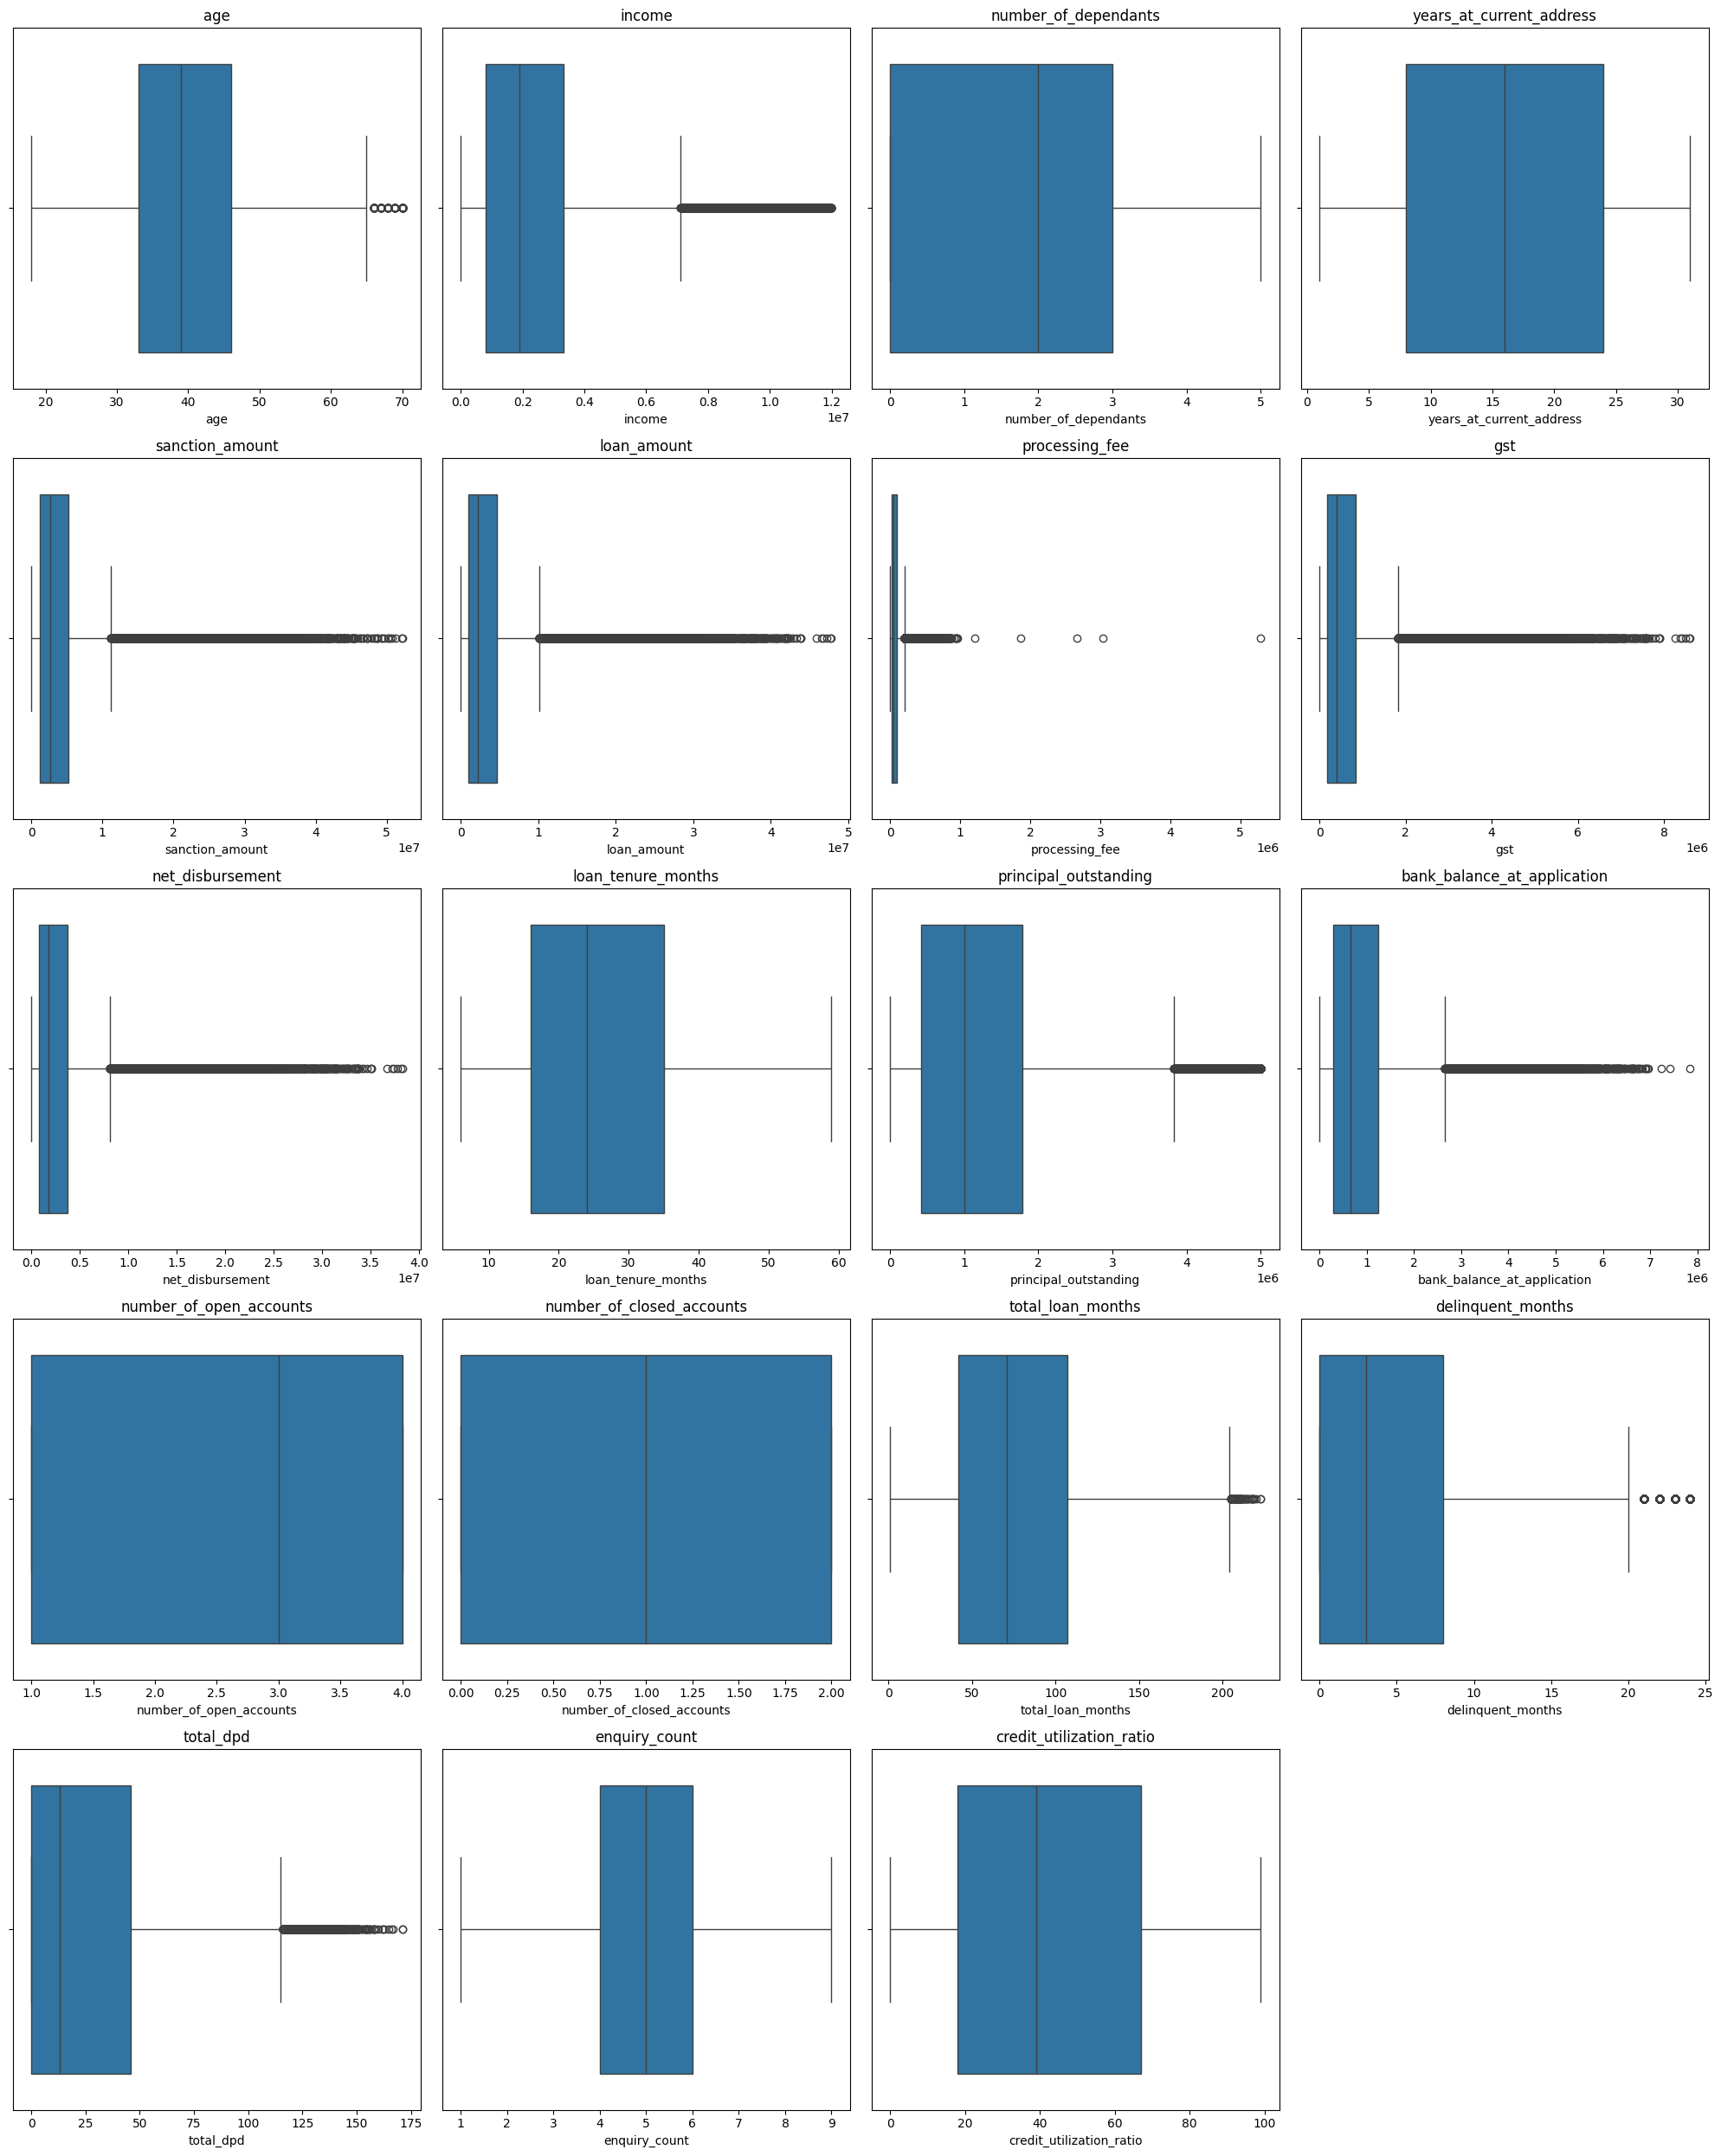

In [19]:
num_plots = len(columns_continuous)
num_cols = 4 # Number of plots per row
num_rows = (num_plots + num_cols - 1) // num_cols # Calculate the number of rows needed

fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 5 * num_rows)) # Adj
axes = axes.flatten() # Flatten the axes array for easier indexing

for i, col in enumerate(columns_continuous):
    sns.boxplot(x=df_train[col], ax=axes[i])
    axes[i].set_title(col) # Set the title to the name of the variable

# If there are any empty plots (if the number of plots isn't a perfect multiple of num_co
for j in range(i + 1, num_rows * num_cols):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


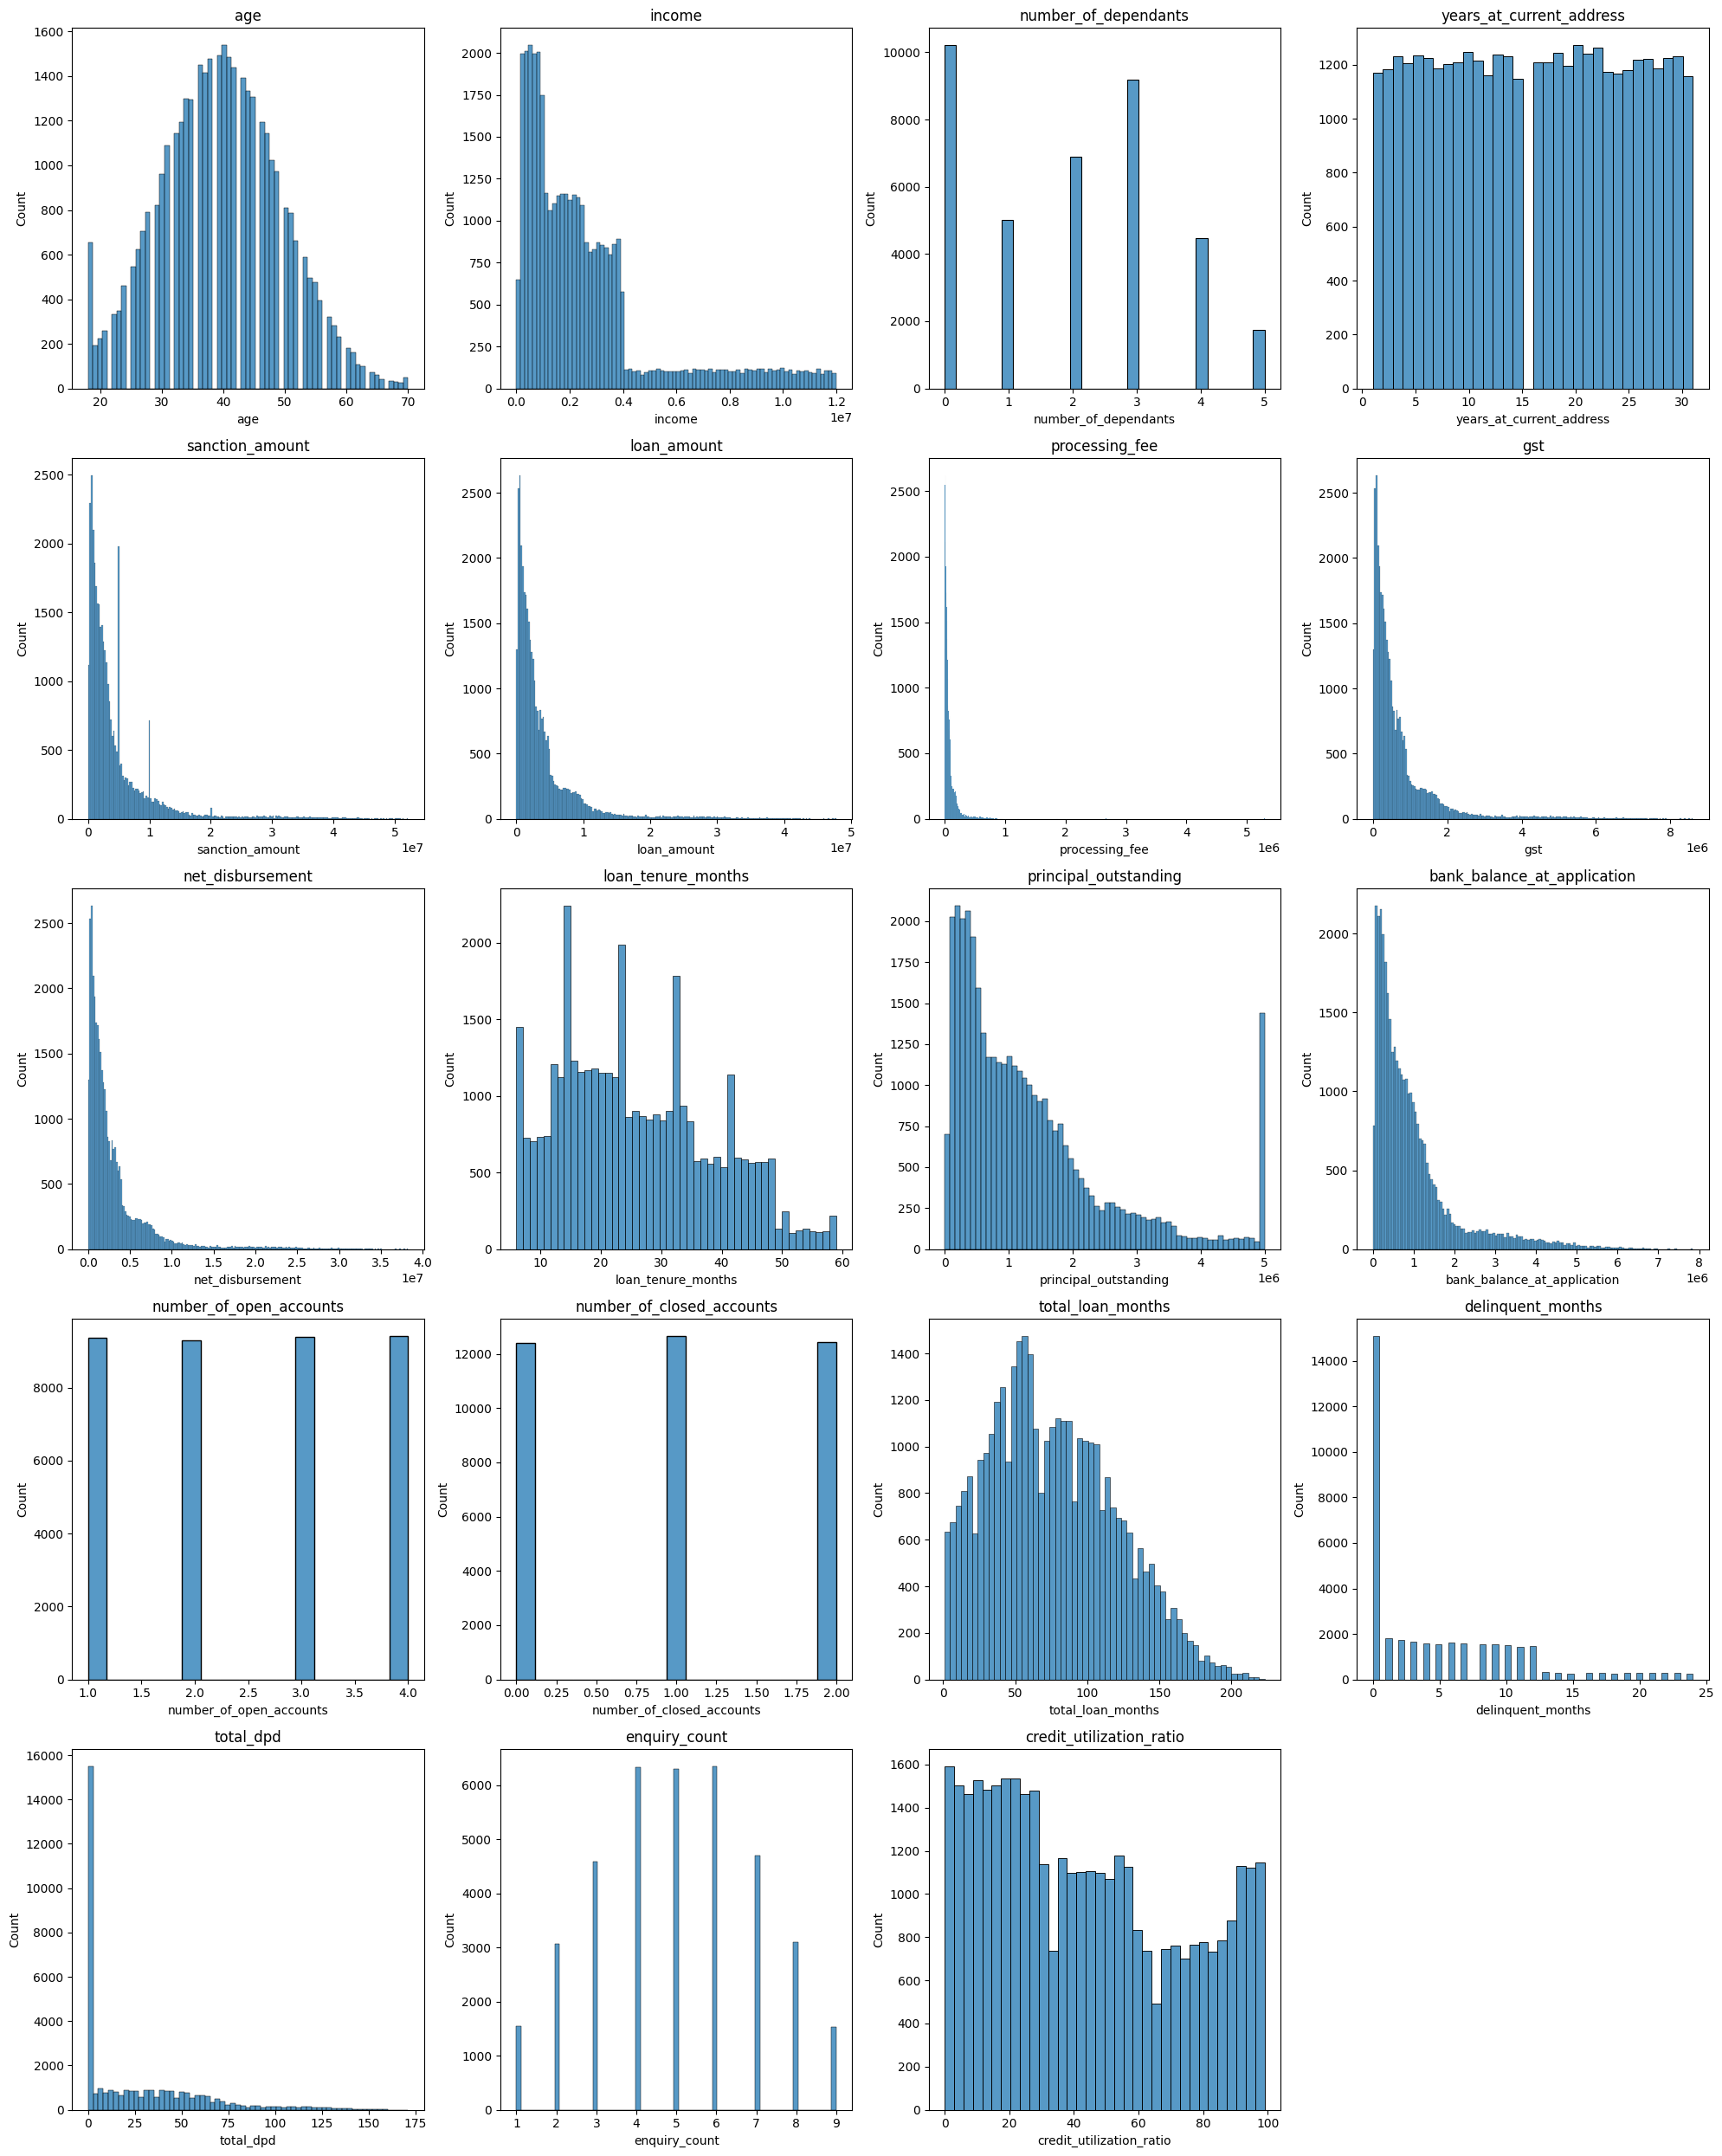

In [20]:
num_plots = len(columns_continuous)
num_cols = 4 # Number of plots per row
num_rows = (num_plots + num_cols - 1) // num_cols # Calculate the number of rows needed

fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 5 * num_rows)) # Adj
axes = axes.flatten() # Flatten the axes array for easier indexing

for i, col in enumerate(columns_continuous):
    sns.histplot(x=df_train[col], ax=axes[i])
    axes[i].set_title(col) # Set the title to the name of the variable

# If there are any empty plots (if the number of plots isn't a perfect multiple of num_co
for j in range(i + 1, num_rows * num_cols):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [21]:
df_train.processing_fee.describe()

,processing_fee
count,37500.00
mean,80290.68
std,113128.14
min,0.00
25%,19220.00
50%,44600.00
75%,92420.00
max,5293543.52


In [22]:
df_train[(df_train.processing_fee/df_train.loan_amount)>0.03][['loan_amount', 'processing_fee']]

,loan_amount,processing_fee
23981,2234000,2669791.02
28174,966000,1214492.67
47089,1738000,1858964.77
29305,2616000,3036378.01
9898,3626000,5293543.52


In [23]:
df_train_1 = df_train[(df_train.processing_fee/df_train.loan_amount)<0.03].copy()
df_train_1[(df_train_1.processing_fee/df_train_1.loan_amount)>0.03][['loan_amount', 'processing_fee']]

,loan_amount,processing_fee


In [24]:
df_test = df_test[(df_test.processing_fee/df_test.loan_amount)<0.03].copy()
df_test.shape

(12497, 33)

In [25]:
for col in columns_categorical:
    print(col, "-->", df_train_1[col].unique())

gender --> ['M' 'F']
marital_status --> ['Married' 'Single']
employment_status --> ['Self-Employed' 'Salaried']
residence_type --> ['Owned' 'Mortgage' 'Rented']
city --> ['Hyderabad' 'Mumbai' 'Chennai' 'Bangalore' 'Pune' 'Kolkata' 'Ahmedabad'
 'Delhi' 'Lucknow' 'Jaipur']
state --> ['Telangana' 'Maharashtra' 'Tamil Nadu' 'Karnataka' 'West Bengal'
 'Gujarat' 'Delhi' 'Uttar Pradesh' 'Rajasthan']
zipcode --> [500001 400001 600001 560001 411001 700001 380001 110001 226001 302001]
loan_purpose --> ['Home' 'Education' 'Personal' 'Auto' 'Personaal']
loan_type --> ['Secured' 'Unsecured']
default --> [0 1]


In [26]:
df_train_1['loan_purpose'] = df_train_1['loan_purpose'].replace('Personaal', 'Personal')
df_test['loan_purpose'] = df_test['loan_purpose'].replace('Personaal', 'Personal')

<h3 align ='center' style='color:yellow'>Exploratory Data Analysis</h3>

In [27]:
columns_continuous

['age',
 'income',
 'number_of_dependants',
 'years_at_current_address',
 'sanction_amount',
 'loan_amount',
 'processing_fee',
 'gst',
 'net_disbursement',
 'loan_tenure_months',
 'principal_outstanding',
 'bank_balance_at_application',
 'number_of_open_accounts',
 'number_of_closed_accounts',
 'total_loan_months',
 'delinquent_months',
 'total_dpd',
 'enquiry_count',
 'credit_utilization_ratio']

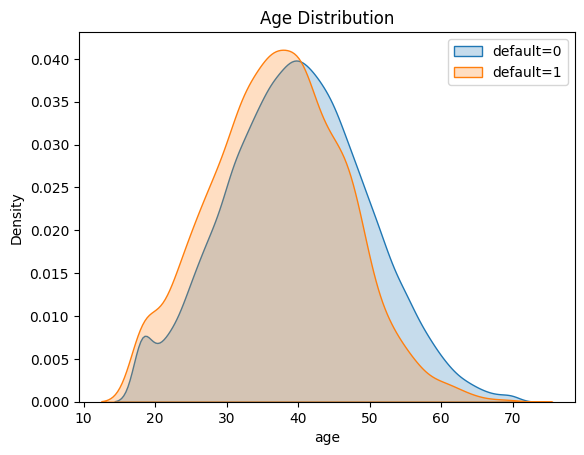

In [28]:
sns.kdeplot(df_train_1['age'][df_train_1['default']==0], fill=True, label='default=0')
sns.kdeplot(df_train_1['age'][df_train_1['default']==1], fill=True, label='default=1')
plt.title('Age Distribution')
plt.legend()
plt.xlabel('age')
plt.show()

Insights:-
1. Orange graph is little bit shifted to the left of blue graph which indicates that people with young age are more likely to default.

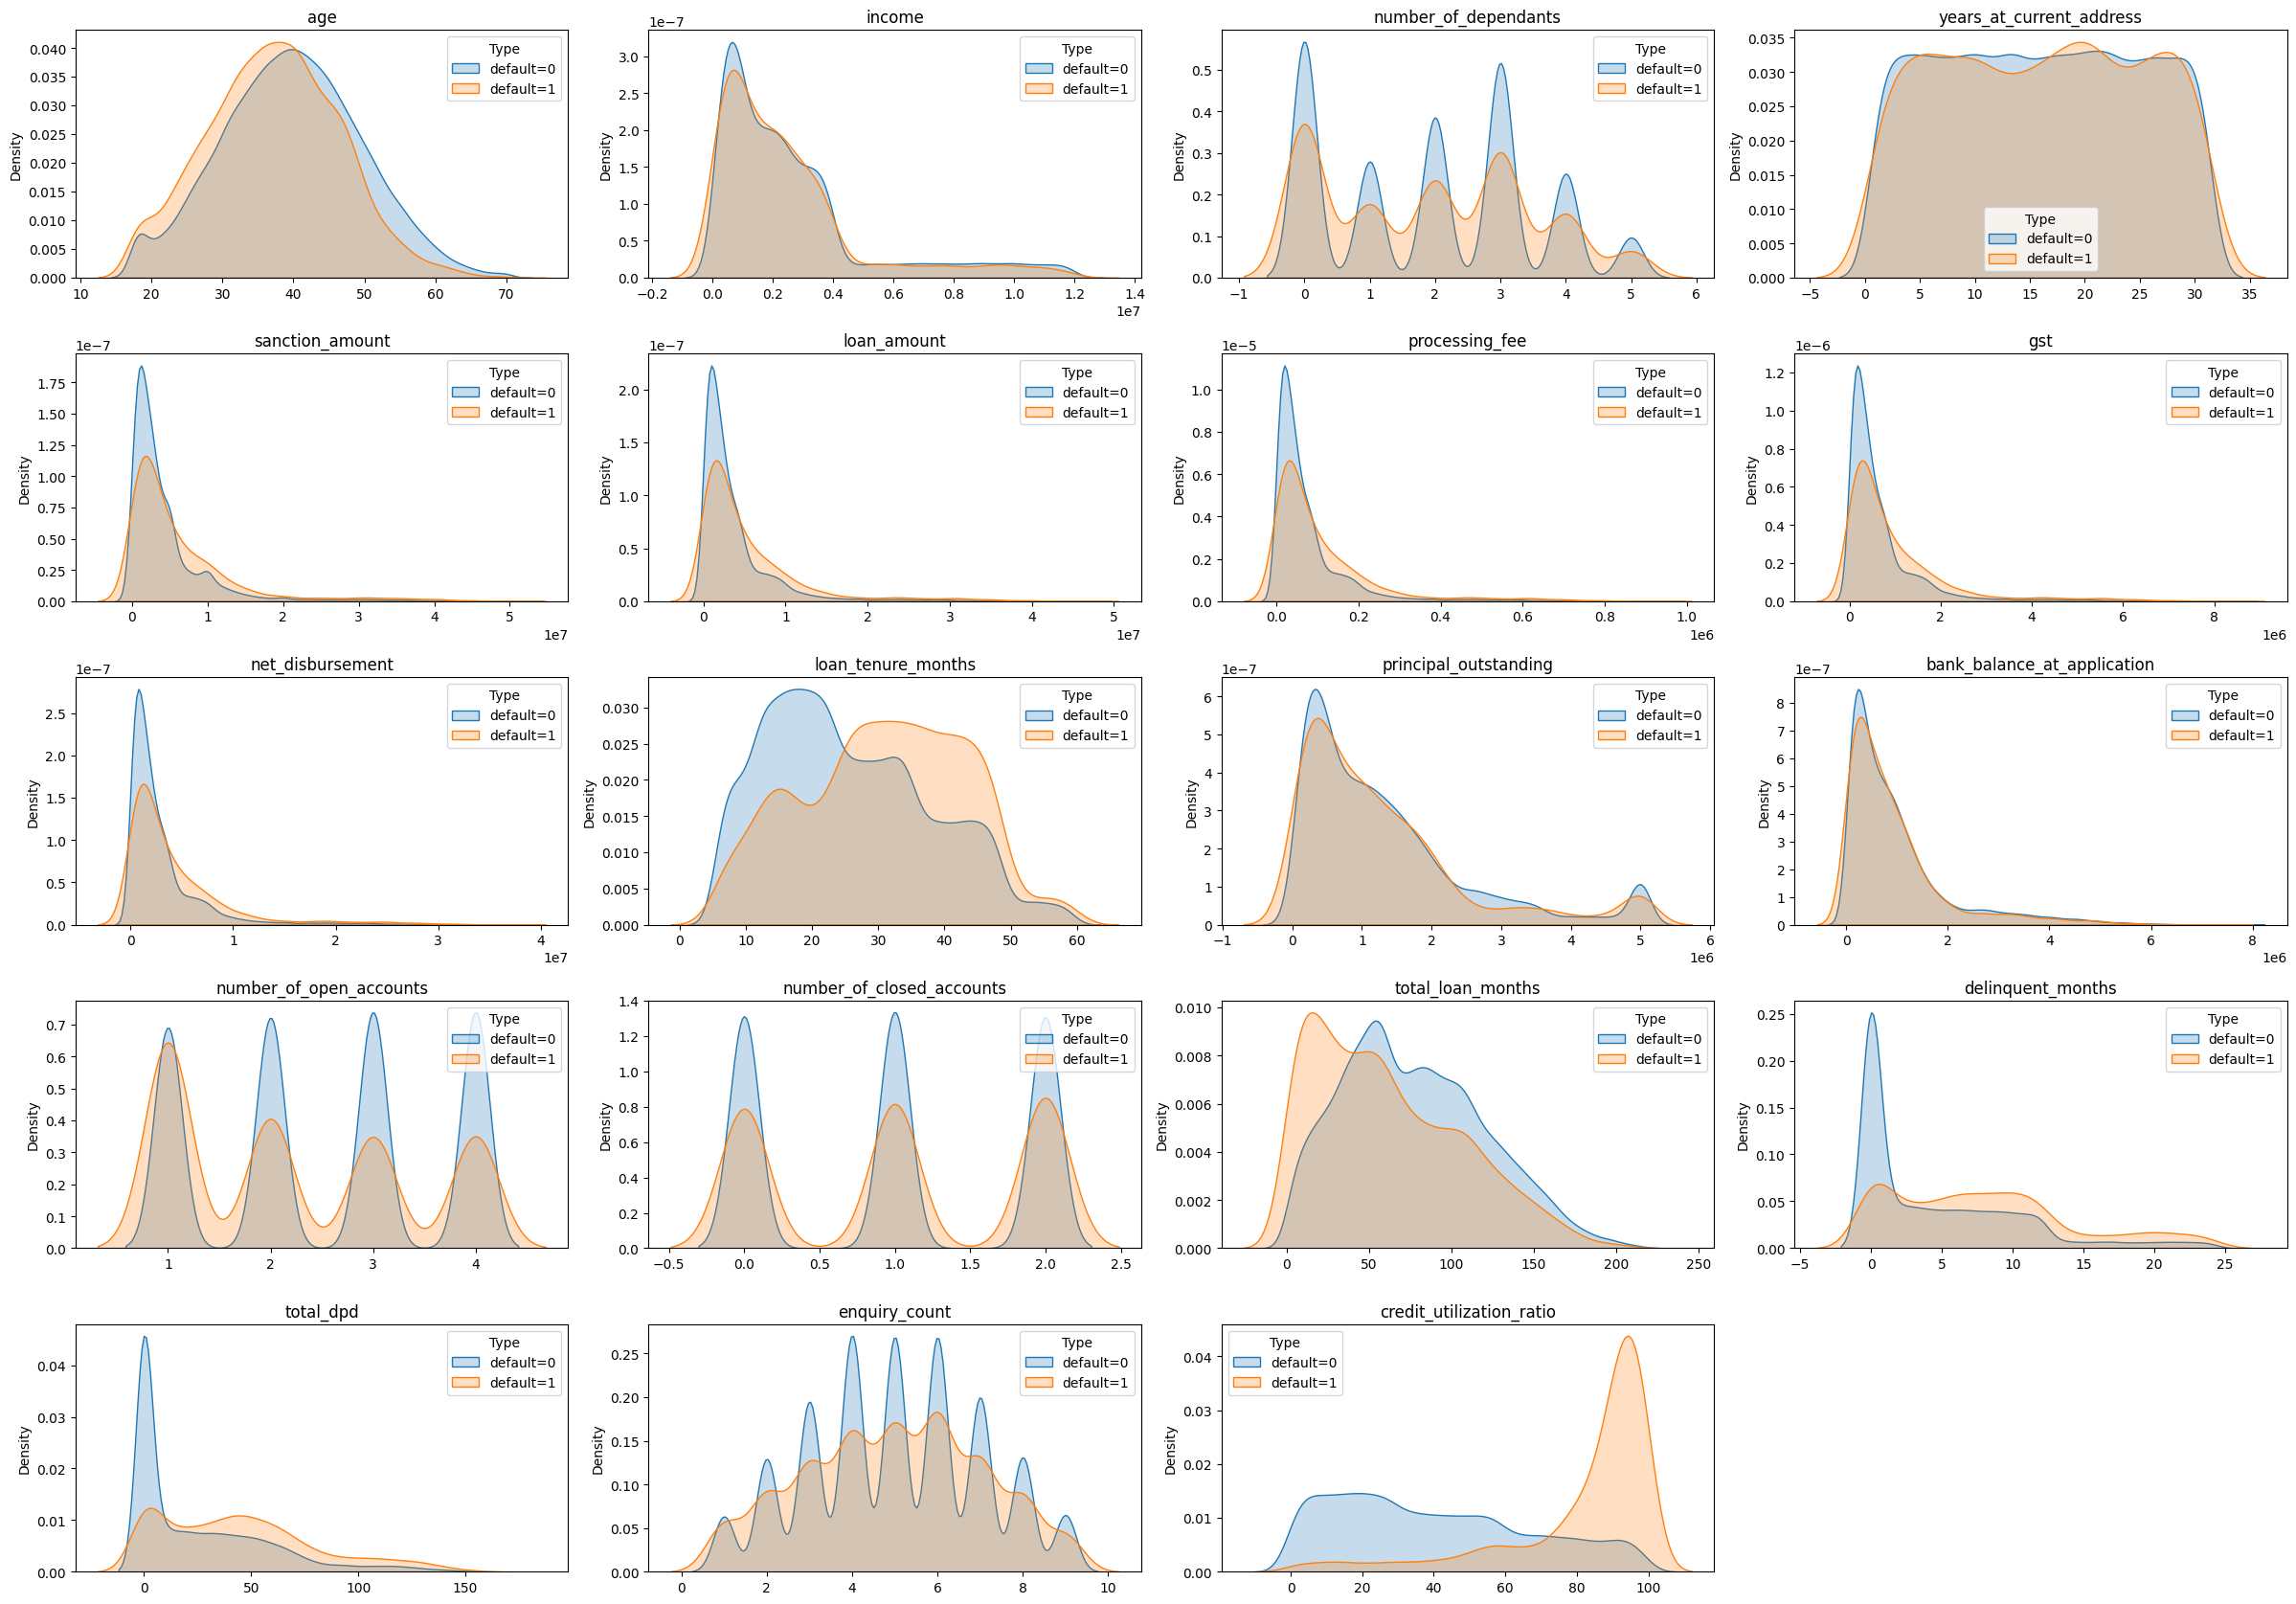

In [29]:
plt.figure(figsize=(24, 20)) # Width, height in inches

for i, col in enumerate(columns_continuous):
    plt.subplot(6, 4, i+1) # 1 row, 4 columns, ith subplot
    sns.kdeplot(df_train_1[col][df_train_1['default']==0], fill=True, label='default=0')
    sns.kdeplot(df_train_1[col][df_train_1['default']==1], fill=True, label='default=1')
    plt.legend(title='Type')
    plt.title(col)
    plt.xlabel('')

plt.tight_layout()
plt.show()

Insights

1. In columns: loan_tenure_months, delinquent_months, total_dpd, credit_utilization, higher values indicate high likelyhood of becoming a default. Hence, these 4 looks like strong predictors
2. In remaining columns the distributions do not give any obvious insights
3. Why loan_amount and income did not give any signs of being strong predictors? May be when we combine these two and get loan to income ratio (LTI), that may have influence on the target variable. We will explore more later


<h3 align ='center' style='color:yellow'>Feature Engineering</h3>

In [30]:
df_train_1['loan_to_income'] = round(df_train_1['loan_amount']/df_train_1['income'], 2)
df_test['loan_to_income'] = round(df_test['loan_amount']/df_test['income'], 2)

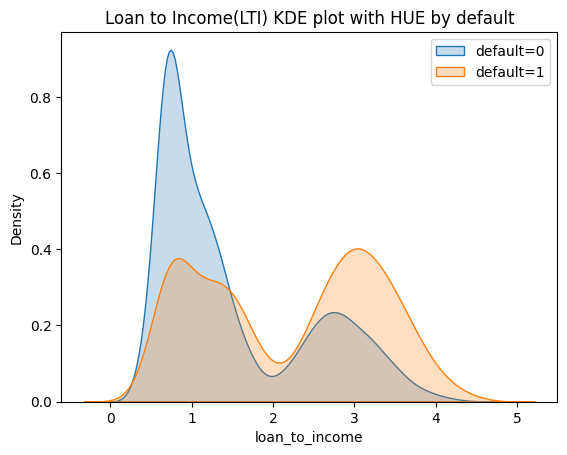

In [31]:
sns.kdeplot(df_train_1[df_train_1['default']==0]['loan_to_income'], fill=True, label='default=0')
sns.kdeplot(df_train_1[df_train_1['default']==1]['loan_to_income'], fill=True, label='default=1')
plt.title(f'Loan to Income(LTI) KDE plot with HUE by default')
plt.legend()
plt.show()

In [32]:
df_train_1.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default',
       'loan_to_income'],
      dtype='object')

In [33]:
df_train_1['delinquency_ratio'] = round(df_train_1['delinquent_months']*100/df_train_1['total_loan_months'], 1)
df_train_1[['delinquent_months', 'total_loan_months', 'delinquency_ratio']].head(3)
df_train_1['delinquency_ratio'].describe()

,delinquency_ratio
count,37488.00
mean,10.33
std,17.30
min,0.00
25%,0.00
50%,3.70
75%,12.90
max,100.00


In [34]:
df_test['delinquency_ratio'] = round(df_test['delinquent_months']*100/df_test['total_loan_months'], 1)

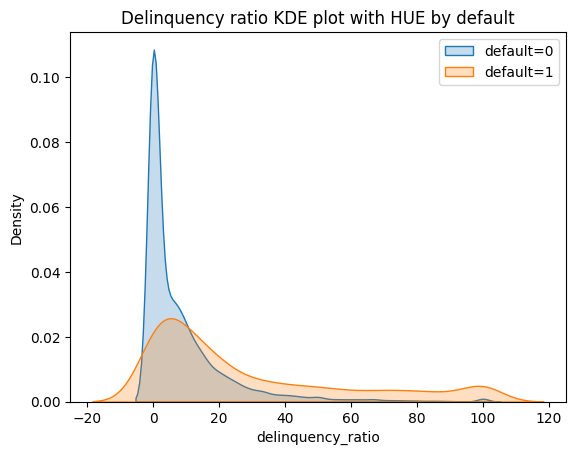

In [35]:
sns.kdeplot(df_train_1[df_train_1['default']==0]['delinquency_ratio'], fill=True, label='default=0')
sns.kdeplot(df_train_1[df_train_1['default']==1]['delinquency_ratio'], fill=True, label='default=1')
plt.title(f'Delinquency ratio KDE plot with HUE by default')
plt.legend()
plt.show()

In [36]:
df_train_1['avg_dpd_per_delinquency'] = np.where(
    df_train_1['delinquent_months']!=0,
    round(df_train_1['total_dpd']/df_train_1['delinquent_months'], 1),
    0)
df_train_1[['total_dpd', 'delinquent_months', 'avg_dpd_per_delinquency']].head(3)
df_train_1['avg_dpd_per_delinquency'].describe()

,avg_dpd_per_delinquency
count,37488.00
mean,3.28
std,2.91
min,0.00
25%,0.00
50%,4.30
75%,5.72
max,10.00


In [37]:
df_test['avg_dpd_per_delinquency'] = np.where(
    df_test['delinquent_months']!=0,
    round(df_test['total_dpd']/df_test['delinquent_months'], 1),
    0)

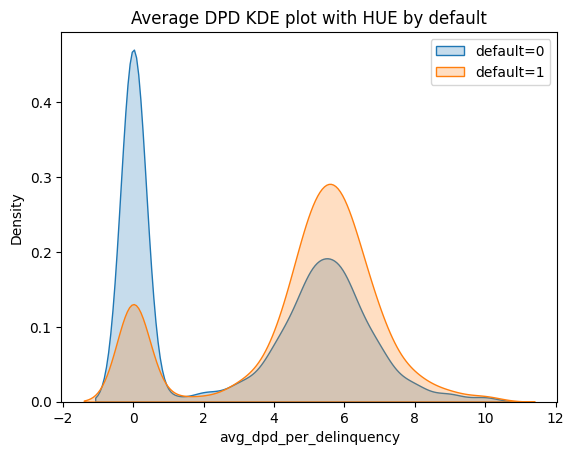

In [38]:
sns.kdeplot(df_train_1[df_train_1['default']==0]['avg_dpd_per_delinquency'], fill=True, label='default=0')
sns.kdeplot(df_train_1[df_train_1['default']==1]['avg_dpd_per_delinquency'], fill=True, label='default=1')
plt.title(f'Average DPD KDE plot with HUE by default')
plt.legend()
plt.show()

### New Feature added: credit_utilization_per_income

In [39]:
df_train_1['credit_utilization_per_income'] = df_train_1['credit_utilization_ratio'] / df_train_1['loan_to_income']

In [40]:
df_test['credit_utilization_per_income'] = df_test['credit_utilization_ratio'] / df_test['loan_to_income']

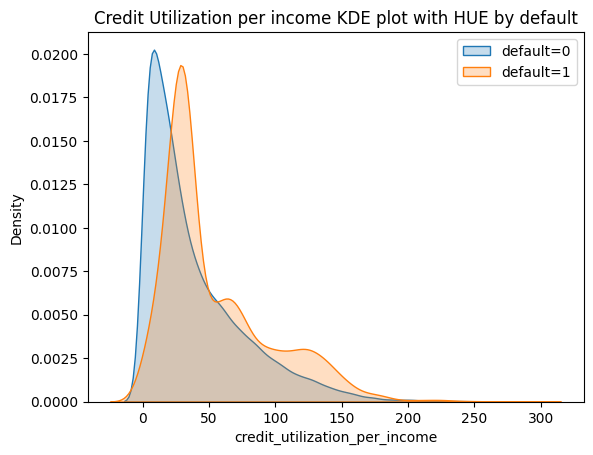

In [41]:
sns.kdeplot(df_train_1[df_train_1['default']==0]['credit_utilization_per_income'], fill=True, label='default=0')
sns.kdeplot(df_train_1[df_train_1['default']==1]['credit_utilization_per_income'], fill=True, label='default=1')
plt.title(f'Credit Utilization per income KDE plot with HUE by default')
plt.legend()
plt.show()

In [42]:
df_train_1.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default',
       'loan_to_income', 'delinquency_ratio', 'avg_dpd_per_delinquency',
       'credit_utilization_per_income'],
      dtype='object')

<h3 align ='center' style='color:yellow'>Feature Selection</h3>

In [43]:
df_train_2 = df_train_1.drop(['cust_id', 'loan_id'], axis=1).copy()
df_test = df_test.drop(['cust_id', 'loan_id'], axis=1)

In [44]:
df_train_3 = df_train_2.drop(['disbursal_date', 'installment_start_dt', 'loan_amount', 'income',
                            'total_loan_months', 'delinquent_months', 'total_dpd'], axis=1)
df_test = df_test.drop(['disbursal_date', 'installment_start_dt', 'loan_amount', 'income',
                        'total_loan_months', 'delinquent_months', 'total_dpd'], axis=1)


In [45]:
df_train_3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 37488 entries, 12746 to 37784
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   age                            37488 non-null  int64  
 1   gender                         37488 non-null  object 
 2   marital_status                 37488 non-null  object 
 3   employment_status              37488 non-null  object 
 4   number_of_dependants           37488 non-null  int64  
 5   residence_type                 37488 non-null  object 
 6   years_at_current_address       37488 non-null  int64  
 7   city                           37488 non-null  object 
 8   state                          37488 non-null  object 
 9   zipcode                        37488 non-null  int64  
 10  loan_purpose                   37488 non-null  object 
 11  loan_type                      37488 non-null  object 
 12  sanction_amount                37488 non-null  

In [46]:
cols_to_scale = df_train_3.select_dtypes(['int64', 'float64'])
cols_to_scale = cols_to_scale.drop(['default', 'zipcode'], axis=1).columns
cols_to_scale

Index(['age', 'number_of_dependants', 'years_at_current_address',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'credit_utilization_per_income'],
      dtype='object')

In [47]:
X_train = df_train_3.drop('default', axis=1)
y_train = df_train_3['default']

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_train.describe()

,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,credit_utilization_per_income
count,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00
mean,0.41,0.39,0.50,418876.24,0.09,0.08,0.08,0.08,0.38,0.26,0.12,0.50,0.50,0.50,0.44,0.29,0.10,0.33,0.14
std,0.19,0.31,0.30,169029.87,0.12,0.11,0.11,0.11,0.23,0.24,0.13,0.37,0.41,0.25,0.30,0.23,0.17,0.29,0.13
min,0.00,0.00,0.00,110001.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.29,0.00,0.23,302001.00,0.02,0.02,0.02,0.02,0.19,0.08,0.03,0.00,0.00,0.38,0.18,0.11,0.00,0.00,0.04
50%,0.40,0.40,0.50,400001.00,0.05,0.05,0.05,0.05,0.34,0.19,0.08,0.67,0.50,0.50,0.39,0.20,0.04,0.43,0.09
75%,0.54,0.60,0.77,560001.00,0.10,0.10,0.10,0.10,0.55,0.35,0.16,1.00,1.00,0.62,0.68,0.51,0.13,0.57,0.20
max,1.00,1.00,1.00,700001.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [48]:
X_test = df_test.drop('default', axis=1)
y_test = df_test['default']

X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])
X_test.describe()

,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,credit_utilization_per_income
count,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00
mean,0.42,0.38,0.50,419759.82,0.09,0.08,0.08,0.08,0.38,0.26,0.12,0.50,0.50,0.50,0.44,0.29,0.11,0.33,0.14
std,0.19,0.31,0.30,168845.35,0.12,0.11,0.11,0.11,0.23,0.25,0.13,0.37,0.41,0.25,0.30,0.23,0.17,0.29,0.13
min,0.00,0.00,0.00,110001.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.29,0.00,0.23,302001.00,0.02,0.02,0.02,0.02,0.19,0.08,0.03,0.00,0.00,0.38,0.18,0.11,0.00,0.00,0.04
50%,0.42,0.40,0.50,411001.00,0.05,0.05,0.05,0.05,0.34,0.20,0.08,0.33,0.50,0.50,0.39,0.20,0.04,0.44,0.09
75%,0.54,0.60,0.77,560001.00,0.10,0.09,0.09,0.09,0.55,0.36,0.16,0.67,1.00,0.62,0.68,0.50,0.13,0.58,0.20
max,1.00,1.00,1.00,700001.00,0.98,0.96,0.96,0.96,1.00,1.00,0.94,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.96


In [49]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    vif_df = pd.DataFrame()
    vif_df['Variable'] = data.columns
    vif_df['VIF'] = [variance_inflation_factor(data.values, i) for i in range(data.shape[1])]
    return vif_df

In [50]:
calculate_vif(X_train[cols_to_scale])

/tmp/ipykernel_1386/1434815231.py:6: UserWarning: The design matrix is poorly conditioned (condition number=2.61e+16). VIF calculations may be numerically unstable.
  vif_df['VIF'] = [variance_inflation_factor(data.values, i) for i in range(data.shape[1])]
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-pack

,Variable,VIF
0,age,1.17
1,number_of_dependants,1.07
2,years_at_current_address,1.00
3,sanction_amount,65.41
4,processing_fee,1000799917193443.50
5,gst,1000799917193443.50
6,net_disbursement,1000799917193443.50
7,loan_tenure_months,1.82
8,principal_outstanding,7.83
9,bank_balance_at_application,5.49


In [51]:
features_to_drop_vif = ['sanction_amount', 'processing_fee', 'gst', 'net_disbursement', 'principal_outstanding']
X_train_1 = X_train.drop(features_to_drop_vif, axis=1)
numeric_columns = X_train_1.select_dtypes(['int64', 'float64']).columns
numeric_columns

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'credit_utilization_per_income'],
      dtype='object')

In [52]:
vif_df = calculate_vif(X_train_1[numeric_columns])
vif_df

,Variable,VIF
0,age,1.13
1,number_of_dependants,1.07
2,years_at_current_address,1.00
3,zipcode,1.00
4,loan_tenure_months,1.79
5,bank_balance_at_application,1.03
6,number_of_open_accounts,1.57
7,number_of_closed_accounts,1.00
8,enquiry_count,1.42
9,credit_utilization_ratio,3.19


In [53]:
selected_numeric_features_vif = vif_df.Variable.values
selected_numeric_features_vif

array(['age', 'number_of_dependants', 'years_at_current_address',
       'zipcode', 'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'enquiry_count', 'credit_utilization_ratio', 'loan_to_income',
       'delinquency_ratio', 'avg_dpd_per_delinquency',
       'credit_utilization_per_income'], dtype=object)

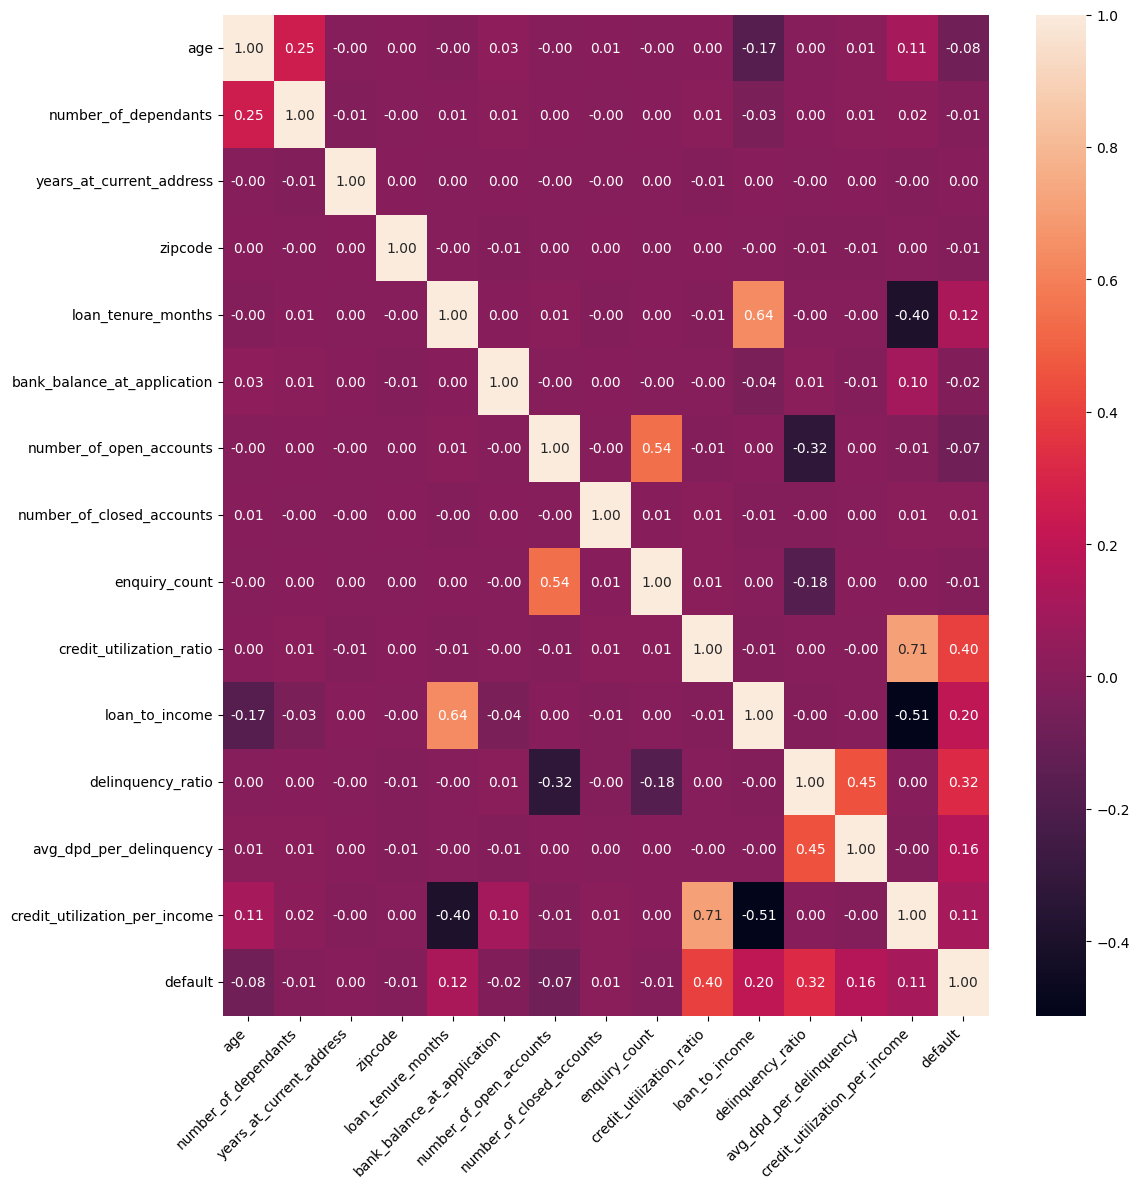

In [54]:
plt.figure(figsize=(12,12))
cm = df_train_3[numeric_columns.append(pd.Index(['default']))].corr()
sns.heatmap(cm, annot=True, fmt='0.2f')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [55]:
columns_categorical

['gender',
 'marital_status',
 'employment_status',
 'residence_type',
 'city',
 'state',
 'zipcode',
 'loan_purpose',
 'loan_type',
 'default']

In [56]:
def calculate_woe_iv(df, feature, target):
    grouped = df.groupby(feature)[target].agg(['count', 'sum'])
    grouped = grouped.rename(columns={'count':'total', 'sum':'good'})
    grouped['bad'] = grouped['total'] - grouped['good']

    total_good = grouped['good'].sum()
    total_bad = grouped['bad'].sum()

    grouped['good_pct'] = grouped['good']/ total_good
    grouped['bad_pct'] = grouped['bad']/ total_bad
    grouped['woe'] = np.log(grouped['good_pct']/grouped['bad_pct'])
    grouped['iv'] = grouped['woe'] * (grouped['good_pct'] - grouped['bad_pct'])

    grouped['woe'] = grouped['woe'].replace([np.inf, -np.inf], 0)
    grouped['iv'] = grouped['iv'].replace([np.inf, -np.inf], 0)

    total_iv = grouped['iv'].sum()
    return grouped, total_iv

grouped, total_iv = calculate_woe_iv(pd.concat([X_train_1, y_train], axis=1), 'loan_purpose', 'default')
grouped

,total,good,bad,good_pct,bad_pct,woe,iv
loan_purpose,,,,,,,
Auto,7447,327,7120,0.10,0.21,-0.72,0.08
Education,5620,559,5061,0.17,0.15,0.16,0.00
Home,11304,1734,9570,0.54,0.28,0.66,0.17
Personal,13117,603,12514,0.19,0.37,-0.67,0.12


In [58]:
iv_values = {}

for feature in X_train_1.columns:
    if X_train_1[feature].dtype == 'object':
        _, iv = calculate_woe_iv(pd.concat([X_train_1, y_train], axis=1), feature, 'default')
    else:
        X_binned = pd.cut(X_train_1[feature], bins=10, labels=False)
        _, iv = calculate_woe_iv(pd.concat([X_binned, y_train], axis=1), feature, 'default')
    iv_values[feature] = iv

iv_values

{'age': np.float64(0.0890689462679479),
 'gender': np.float64(0.00047449502170914947),
 'marital_status': np.float64(0.001129766845390142),
 'employment_status': np.float64(0.003953046301722585),
 'number_of_dependants': np.float64(0.0019380899135053508),
 'residence_type': np.float64(0.246745268718145),
 'years_at_current_address': np.float64(0.0020800513608156363),
 'city': np.float64(0.0019059578709781529),
 'state': np.float64(0.0019005589806779287),
 'zipcode': np.float64(0.0016677413243392572),
 'loan_purpose': np.float64(0.3691197842282755),
 'loan_type': np.float64(0.16319324904149224),
 'loan_tenure_months': np.float64(0.21893515090196278),
 'bank_balance_at_application': np.float64(0.0063187993277516365),
 'number_of_open_accounts': np.float64(0.08463134083005877),
 'number_of_closed_accounts': np.float64(0.0011964272592421567),
 'enquiry_count': np.float64(0.007864214085342608),
 'credit_utilization_ratio': np.float64(2.352965568168245),
 'loan_to_income': np.float64(0.47641

In [59]:
pd.set_option('display.float_format', lambda x: '{:.3f}'.format(x))

iv_df = pd.DataFrame(list(iv_values.items()), columns=['Feature', 'IV'])
iv_df = iv_df.sort_values(by='IV', ascending=False)
iv_df

,Feature,IV
17,credit_utilization_ratio,2.353
19,delinquency_ratio,0.717
18,loan_to_income,0.476
20,avg_dpd_per_delinquency,0.402
10,loan_purpose,0.369
5,residence_type,0.247
12,loan_tenure_months,0.219
21,credit_utilization_per_income,0.196
11,loan_type,0.163
0,age,0.089


In [60]:
selected_features_iv = [feature for feature, iv in iv_values.items() if iv > 0.02]
selected_features_iv

['age',
 'residence_type',
 'loan_purpose',
 'loan_type',
 'loan_tenure_months',
 'number_of_open_accounts',
 'credit_utilization_ratio',
 'loan_to_income',
 'delinquency_ratio',
 'avg_dpd_per_delinquency',
 'credit_utilization_per_income']

<h3 align ='center' style='color:yellow'>Feature Encoding</h3>

In [61]:
X_train_reduced = X_train_1[selected_features_iv]
X_test_reduced = X_test[selected_features_iv]

In [62]:
X_train_reduced.head()

,age,residence_type,loan_purpose,loan_type,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,credit_utilization_per_income
12746,0.788,Owned,Home,Secured,0.415,1.000,0.364,0.415,0.132,0.590,0.060
32495,0.500,Owned,Education,Secured,0.830,0.667,0.051,0.307,0.062,0.620,0.011
43675,0.385,Mortgage,Home,Secured,0.491,0.000,0.000,0.759,0.222,0.560,0.000
9040,0.462,Mortgage,Education,Secured,0.642,0.667,0.879,0.194,0.000,0.000,0.264
13077,0.769,Owned,Personal,Unsecured,0.170,0.000,0.717,0.047,0.000,0.000,0.488


In [63]:
X_train_encoded = pd.get_dummies(X_train_reduced, drop_first=True)
X_test_encoded = pd.get_dummies(X_test_reduced, drop_first=True)

X_train_encoded.head()

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,credit_utilization_per_income,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
12746,0.788,0.415,1.000,0.364,0.415,0.132,0.590,0.060,True,False,False,True,False,False
32495,0.500,0.830,0.667,0.051,0.307,0.062,0.620,0.011,True,False,True,False,False,False
43675,0.385,0.491,0.000,0.000,0.759,0.222,0.560,0.000,False,False,False,True,False,False
9040,0.462,0.642,0.667,0.879,0.194,0.000,0.000,0.264,False,False,True,False,False,False
13077,0.769,0.170,0.000,0.717,0.047,0.000,0.000,0.488,True,False,False,False,True,True


<h3 align ='center' style='color:yellow'>Model Training</h3>

## Attempt 1:
    1. Logistic Regression, Random forest, XG boost
    2. No handling of class imbalance

In [64]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_curve
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

model = LogisticRegression()
model.fit(X_train_encoded, y_train)
y_pred = model.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11423
           1       0.85      0.72      0.78      1074

    accuracy                           0.96     12497
   macro avg       0.91      0.86      0.88     12497
weighted avg       0.96      0.96      0.96     12497



In [65]:
model = RandomForestClassifier()
model.fit(X_train_encoded, y_train)
y_pred = model.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11423
           1       0.85      0.71      0.78      1074

    accuracy                           0.96     12497
   macro avg       0.91      0.85      0.88     12497
weighted avg       0.96      0.96      0.96     12497



In [66]:
model = XGBClassifier()
model.fit(X_train_encoded, y_train)
y_pred = model.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     11423
           1       0.82      0.75      0.79      1074

    accuracy                           0.96     12497
   macro avg       0.90      0.87      0.88     12497
weighted avg       0.96      0.96      0.96     12497



In [67]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'C': np.logspace(-4, 4, 20), # Logarithmically spaced values from 10^-4 to 10^4
    'solver': ['lbfgs', 'saga', 'liblinear', 'newton-cg'] # Algorithm to use in the optimization problem
}

# Create the Logistic Regression model
log_reg = LogisticRegression(max_iter=10000) # Increased max_iter for convergence

# Set up RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=log_reg,
    param_distributions=param_dist,
    n_iter=50, # Number of parameter settings that are sampled
    scoring='f1',
    cv=3, # 5-fold cross-validation
    verbose=2,
    random_state=42, # Set a random state for reproducibility
    n_jobs=-1 # Use all available cores
)

# Fit the RandomizedSearchCV to the training data_and_notebooks
random_search.fit(X_train_encoded, y_train)

# Print the best parameters and best score
print(f"Best Parameters: {random_search.best_params_}")
print(f"Best Score: {random_search.best_score_}")

best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test_encoded)
print("Classification Report:")
print(classification_report(y_test, y_pred))


Fitting 3 folds for each of 50 candidates, totalling 150 fits


KeyboardInterrupt: 

In [ ]:
from scipy.stats import uniform, randint
from sklearn.model_selection import RandomizedSearchCV

# Define parameter distribution for RandomizedSearchCV
param_dist = {
    'n_estimators':[100,150,200,250,300],
    'max_depth':[3,4,5,6,7,8,9,10],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'scale_pos_weight':[1,2,3,5,7,10],
    'reg_alpha': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0], # L1 regularization term
    'reg_lambda': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0] # L2 regularization term
}

xgb = XGBClassifier()

random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_dist, n_iter=100,
                                   scoring='f1', cv=3, verbose=1, n_jobs=-1, random_state=42)

random_search.fit(X_train_encoded, y_train)

# Print the best parameters and best score
print(f"Best Parameters: {random_search.best_params_}")
print(f"Best Score: {random_search.best_score_}")

best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test_encoded)
print("Classification Report:")
print(classification_report(y_test, y_pred))


Fitting 3 folds for each of 100 candidates, totalling 300 fits
Best Parameters: {'subsample': 0.8, 'scale_pos_weight': 2, 'reg_lambda': 1.0, 'reg_alpha': 5.0, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.2, 'colsample_bytree': 0.9}
Best Score: 0.788655597605462
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98     11423
           1       0.77      0.83      0.80      1074

    accuracy                           0.96     12497
   macro avg       0.88      0.90      0.89     12497
weighted avg       0.97      0.96      0.97     12497



## Attempt 2:
    1. Logistic Regression, Random forest, XG boost
    2. Handling of class imbalance by undersampling

In [69]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek

rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train_encoded, y_train)
y_train_rus.value_counts()

,count
default,
0,3223
1,3223


In [ ]:
model = LogisticRegression()
model.fit(X_train_rus, y_train_rus)
y_pred = model.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       1.00      0.91      0.95     11423
           1       0.51      0.95      0.67      1074

    accuracy                           0.92     12497
   macro avg       0.75      0.93      0.81     12497
weighted avg       0.95      0.92      0.93     12497



## Attempt 3:
    1. Logistic Regression
    2. Handle class imbalance by SMOTE Tomek
    3. Parameter tuning using Optuna

In [70]:
smt = SMOTETomek(random_state=42)
X_train_smt, y_train_smt = smt.fit_resample(X_train_encoded, y_train)
y_train_smt.value_counts()

,count
default,
0,34212
1,34212


In [71]:
model = LogisticRegression()
model.fit(X_train_smt, y_train_smt)
y_pred = model.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11423
           1       0.56      0.94      0.70      1074

    accuracy                           0.93     12497
   macro avg       0.78      0.94      0.83     12497
weighted avg       0.96      0.93      0.94     12497



In [73]:
!pip install optuna
import optuna
from sklearn.metrics import make_scorer, f1_score
from sklearn.model_selection import cross_val_score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [74]:
def objective(trial):
    param = {
        'C': trial.suggest_float('C', 1e-4, 1e4, log=True),
        'solver': trial.suggest_categorical('solver', ['lbfgs', 'liblinear', 'saga', 'newton-cg']),
        'tol': trial.suggest_float('tol', 1e-6, 1e-1, log=True),
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])
    }

    model = LogisticRegression(**param, max_iter=10000)

    f1_scorer = make_scorer(f1_score, average='macro')
    scores = cross_val_score(model, X_train_smt, y_train_smt, cv=3, scoring=f1_scorer, n_jobs=-1)

    return np.mean(scores)

study_logistic = optuna.create_study(direction='maximize')
study_logistic.optimize(objective, n_trials=50)

[I 2026-10-30 12:58:30,494] A new study created in memory with name: no-name-1229fbe1-3d61-40d8-bd6a-fd067642df01
[I 2026-10-30 12:58:36,535] Trial 0 finished with value: 0.783999352631857 and parameters: {'C': 0.000110597572303969, 'solver': 'liblinear', 'tol': 9.302694836057967e-06, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.783999352631857.
[I 2026-10-30 12:58:38,804] Trial 1 finished with value: 0.9458519362149124 and parameters: {'C': 1874.385048181516, 'solver': 'saga', 'tol': 0.00013960210509203746, 'class_weight': None}. Best is trial 1 with value: 0.9458519362149124.
[I 2026-10-30 12:58:39,271] Trial 2 finished with value: 0.7965105253945984 and parameters: {'C': 0.0001450328033020636, 'solver': 'liblinear', 'tol': 0.014276855010593678, 'class_weight': 'balanced'}. Best is trial 1 with value: 0.9458519362149124.
[I 2026-10-30 12:58:39,483] Trial 3 finished with value: 0.7726664749266714 and parameters: {'C': 0.001921709153047328, 'solver': 'lbfgs', 'tol': 0.081

In [75]:
print('Best trial:')
trial = study_logistic.best_trial
print('  F1-score: {}'.format(trial.value))
print('  Params: ')
for key, value in trial.params.items():
    print('    {}: {}'.format(key, value))

best_model_logistic = LogisticRegression(**study_logistic.best_params)
best_model_logistic.fit(X_train_smt, y_train_smt)

# Evaluate on the test set
y_pred = best_model_logistic.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)


Best trial:
  F1-score: 0.946114450923493
  Params: 
    C: 4.9616019867086365
    solver: saga
    tol: 0.002357839545172893
    class_weight: None
              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11423
           1       0.56      0.95      0.70      1074

    accuracy                           0.93     12497
   macro avg       0.78      0.94      0.83     12497
weighted avg       0.96      0.93      0.94     12497



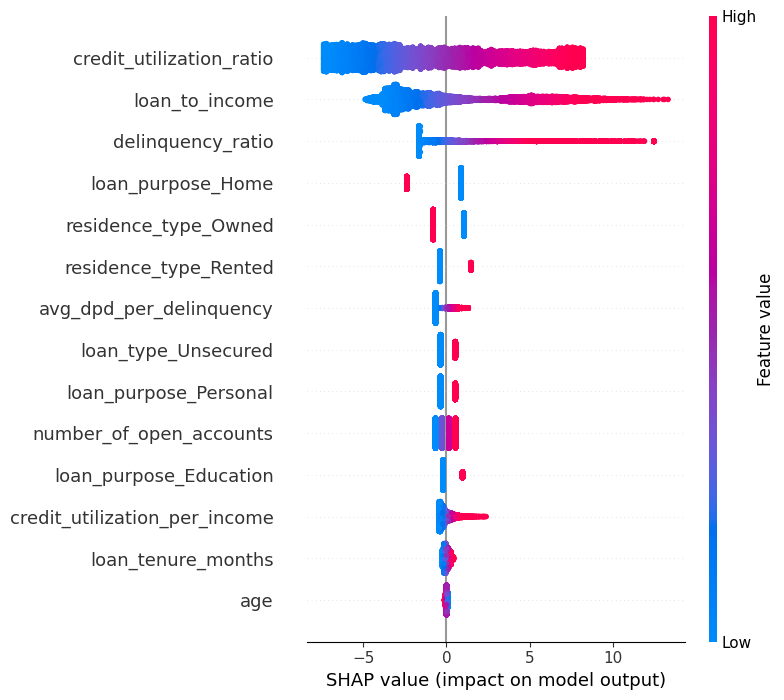

In [78]:
# Create a SHAP explainer specifically for linear models using background data
import shap

# Convert any boolean columns in the test dataset to numeric (0/1) to prevent type errors in the plot
X_test_encoded_numeric = X_test_encoded.astype(float)

# LinearExplainer needs the model and background data to handle feature correlation/masking
explainer = shap.LinearExplainer(best_model_logistic, X_train_encoded.astype(float))
shap_explanation = explainer(X_test_encoded_numeric)

# Summary plot using the raw SHAP values from the explanation object
shap.summary_plot(shap_explanation.values, X_test_encoded_numeric)

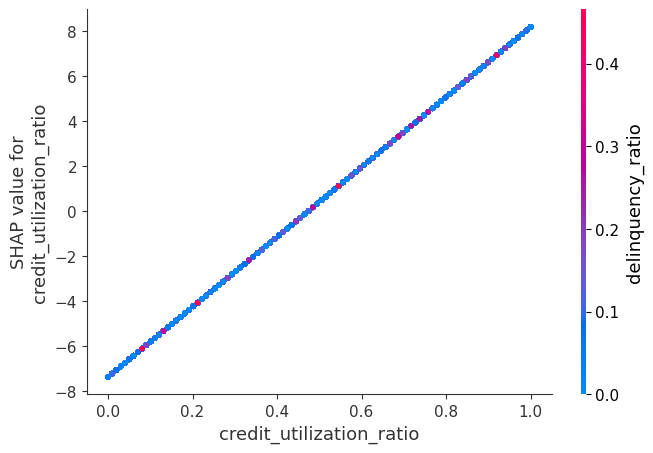

In [81]:
shap.dependence_plot("credit_utilization_ratio", shap_explanation.values, X_test_encoded_numeric)

## Attempt 4:
    1. XG Boost
    2. Handle class imbalance by SMOTE Tomek
    3. Parameter tuning using Optuna

In [ ]:
# Define the objective function for Optuna
def objective(trial):
    param = {
        'objective': 'binary:logistic',
        'eval_metric': 'logloss',
        'verbosity': 0,
        'booster': 'gbtree',
        'lambda': trial.suggest_float('lambda', 1e-3, 10.0, log=True),
        'alpha': trial.suggest_float('alpha', 1e-3, 10.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.4, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'eta': trial.suggest_float('eta', 0.01, 0.3),
        'gamma': trial.suggest_float('gamma', 0, 10),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'max_delta_step': trial.suggest_int('max_delta_step', 0, 10)
    }

    model = XGBClassifier(**param)

    # Calculate the cross-validated f1_score
    f1_scorer = make_scorer(f1_score, average='macro')
    scores = cross_val_score(model, X_train_smt, y_train_smt, cv=3, scoring=f1_scorer, n_jobs=-1)

    return np.mean(scores)

study_xgb = optuna.create_study(direction='maximize')
study_xgb.optimize(objective, n_trials=50)


[I 2026-08-21 14:04:23,536] A new study created in memory with name: no-name-ebaa3c8e-fe7a-4883-a6ef-f42b9534fa16
[I 2026-08-21 14:04:24,331] Trial 0 finished with value: 0.966871705379857 and parameters: {'lambda': 0.500841199253851, 'alpha': 0.021192011457375697, 'subsample': 0.6519893135465349, 'colsample_bytree': 0.748091473690911, 'max_depth': 8, 'eta': 0.1103569090874651, 'gamma': 7.990683004051007, 'scale_pos_weight': 2.9802268422915654, 'min_child_weight': 5, 'max_delta_step': 7}. Best is trial 0 with value: 0.966871705379857.
[I 2026-08-21 14:04:24,973] Trial 1 finished with value: 0.9692648364700136 and parameters: {'lambda': 0.11164731020814635, 'alpha': 0.37275830008742067, 'subsample': 0.4155935784281114, 'colsample_bytree': 0.7292014826171446, 'max_depth': 7, 'eta': 0.2303941439358646, 'gamma': 6.327730889125828, 'scale_pos_weight': 1.9348638408434335, 'min_child_weight': 9, 'max_delta_step': 2}. Best is trial 1 with value: 0.9692648364700136.
[I 2026-08-21 14:04:26,068] 

In [ ]:
print('Best trial:')
trial = study_xgb.best_trial
print('  F1-score: {}'.format(trial.value))
print('  Params: ')
for key, value in trial.params.items():
    print('    {}: {}'.format(key, value))

best_params = study_xgb.best_params
best_model_xgb = XGBClassifier(**best_params)
best_model_xgb.fit(X_train_smt, y_train_smt)

# Evaluate on the test set
y_pred = best_model_xgb.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)


Best trial:
  F1-score: 0.9748123170544859
  Params: 
    lambda: 0.006105351767019282
    alpha: 0.08324041896048935
    subsample: 0.8889132542795861
    colsample_bytree: 0.7844197078296414
    max_depth: 10
    eta: 0.11458991324719378
    gamma: 2.4456955051017775
    scale_pos_weight: 1.6123951055572654
    min_child_weight: 2
    max_delta_step: 5
              precision    recall  f1-score   support

           0       0.99      0.96      0.98     11423
           1       0.69      0.87      0.77      1074

    accuracy                           0.96     12497
   macro avg       0.84      0.92      0.87     12497
weighted avg       0.96      0.96      0.96     12497



## Finally, we are going with best model of Logistic regression as the recall is above 90% as per client's requirement

## Attempt 5:
1. Bayesian optimization
2. Model is Logistic Regression
3. Class balanced using SMOTE Tomek

In [ ]:
from bayes_opt import BayesianOptimization

def optimize_log_reg(C, max_iter):
    model = LogisticRegression(C=C, max_iter=int(max_iter), solver='liblinear')
    # Perform 5-fold cross-validation
    scores = cross_val_score(model, X_train_encoded, y_train, cv=5, scoring='roc_auc')
    # We want to maximize the AUC-ROC score
    return scores.mean()

# Define the parameter space
param_bounds = {
    'C': (0.001, 10.0),
    'max_iter': (50, 500)
}

# Initialize the Bayesian optimizer
optimizer = BayesianOptimization(
    f=optimize_log_reg,
    pbounds=param_bounds,
    random_state=42
)

# Perform the optimization
optimizer.maximize(init_points=10, n_iter=50)

|   iter    |  target   |     C     | max_iter  |
-------------------------------------------------
| 1         | 0.9827015 | 3.7460266 | 477.82143 |
| 2         | 0.9827335 | 7.3202074 | 319.39631 |
| 3         | 0.9825491 | 1.5610303 | 120.19753 |
| 4         | 0.9819635 | 0.5817780 | 439.77926 |
| 5         | 0.9827284 | 6.0115490 | 368.63266 |
| 6         | 0.9804213 | 0.2068243 | 486.45943 |
| 7         | 0.9827347 | 8.3245939 | 145.55259 |
| 8         | 0.9825905 | 1.8190678 | 132.53202 |
| 9         | 0.9826828 | 3.0431181 | 286.14039 |
| 10        | 0.9827106 | 4.3200182 | 181.05311 |
| 11        | 0.9827343 | 7.8519744 | 118.46654 |
| 12        | 0.9827381 | 9.9913716 | 144.91808 |
| 13        | 0.9827314 | 6.5510892 | 471.05374 |
| 14        | 0.9827106 | 4.4255519 | 310.31656 |
| 15        | 0.9827070 | 4.0940638 | 298.40183 |
| 16        | 0.9827382 | 9.9417871 | 109.00352 |
| 17        | 0.9813934 | 0.3565494 | 106.58386 |
| 18        | 0.9827383 | 9.9035271 | 291.36659 |


In [ ]:
# Extract the best parameters
best_params = optimizer.max['params']
best_params['max_iter'] = int(best_params['max_iter'])

# Train the final model with the best parameters
final_model = LogisticRegression(**best_params, solver='liblinear')
final_model.fit(X_train_encoded, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",np.float64(9.962214315771002)
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",135
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gi

In [ ]:
# Evaluate the final model on the test set
y_pred = final_model.predict(X_test_encoded)
y_prob = final_model.predict_proba(X_test_encoded)[:, 1]

# Print the classification report and AUC-ROC score
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98     11423
           1       0.84      0.74      0.78      1074

    accuracy                           0.97     12497
   macro avg       0.91      0.86      0.88     12497
weighted avg       0.96      0.97      0.96     12497



In [ ]:
print("AUC-ROC Score:", roc_auc_score(y_test, y_pred))

AUC-ROC Score: 0.8620618403426976


## Attempt 6:
1. Grid Search CV
2. XG Boost model
3. Balanced with SMOTE Tomek

In [ ]:
from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTETomek
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

# Define parameter distribution for RandomizedSearchCV
param_grid = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [50, 100, 200],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0]
}

xgb = XGBClassifier(random_state=42)

grid_search = GridSearchCV(estimator=xgb, param_grid=param_grid,
                                   scoring='roc_auc', cv=5, verbose=1, n_jobs=-1)

grid_search.fit(X_train_encoded, y_train)

# Print the best parameters and best score
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Score: {grid_search.best_score_}")

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test_encoded)
print("Classification Report:")
print(classification_report(y_test, y_pred))


Fitting 5 folds for each of 243 candidates, totalling 1215 fits
Best Parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}
Best Score: 0.9875132823935301
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98     11423
           1       0.85      0.75      0.80      1074

    accuracy                           0.97     12497
   macro avg       0.91      0.87      0.89     12497
weighted avg       0.97      0.97      0.97     12497



## SHAP

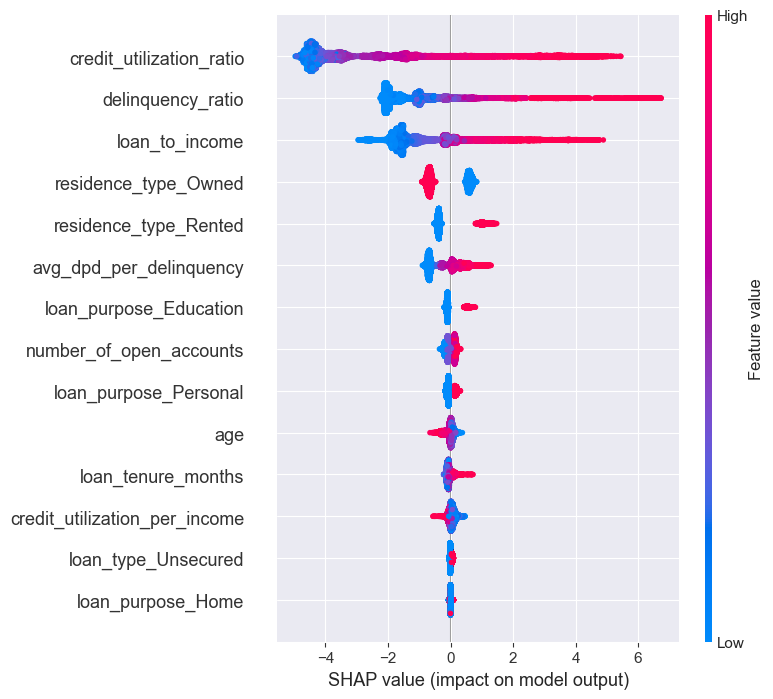

In [ ]:
# Create a SHAP explainer
import shap

explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test_encoded)

# Summary plot
shap.summary_plot(shap_values, X_test_encoded)

1. credit_utilization_ratio: High values (red) increase the likelihood of default, as shown by positive SHAP values.
2. delinquency_ratio: Similarly, higher values increase the risk, shown by positive SHAP values.
3. loan_to_income: Higher values (red) also increase the default risk.
4. residence_type_Owned and residence_type_Rented: Different impacts based on whether the residence is owned or rented.
5. avg_dpd_per_delinquency: Higher average days past due per delinquency increase the risk.

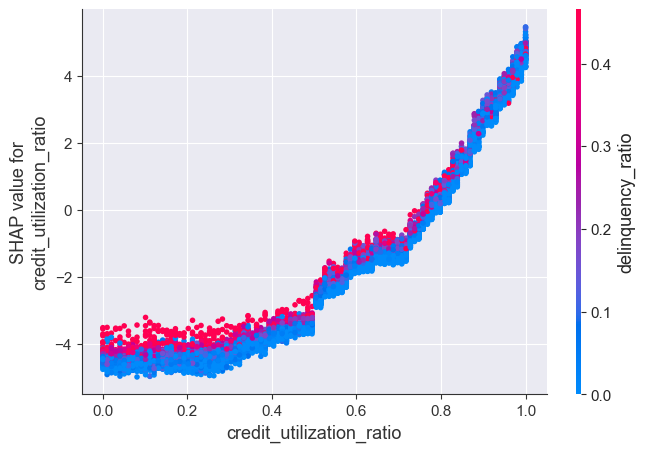

In [ ]:
# Dependence plot for a specific feature
shap.dependence_plot("credit_utilization_ratio", shap_values, X_test_encoded)

In [ ]:
# plot for a single prediction
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[0,:], X_test_encoded.iloc[0,:])

<h3 align ='center' style='color:yellow'>Model Evaluation</h3>

In [ ]:
y_pred = best_model_logistic.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11423
           1       0.56      0.95      0.70      1074

    accuracy                           0.93     12497
   macro avg       0.78      0.94      0.83     12497
weighted avg       0.96      0.93      0.94     12497



In [ ]:
from sklearn.metrics import roc_curve, auc

probabilities = best_model_logistic.predict_proba(X_test_encoded)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, probabilities)
fpr[:10], tpr[:10], thresholds[:10]

(array([0.        , 0.        , 0.        , 0.00008754, 0.00008754,
        0.00017509, 0.00017509, 0.00026263, 0.00026263, 0.00035017]),
 array([0.        , 0.0009311 , 0.15828678, 0.15828678, 0.16759777,
        0.16759777, 0.22160149, 0.22160149, 0.24022346, 0.24022346]),
 array([       inf, 1.        , 0.99949817, 0.99949308, 0.99940608,
        0.99940439, 0.99872125, 0.99872117, 0.99835875, 0.99832454]))

In [ ]:
area = auc(fpr, tpr)
area

0.9837803960156833

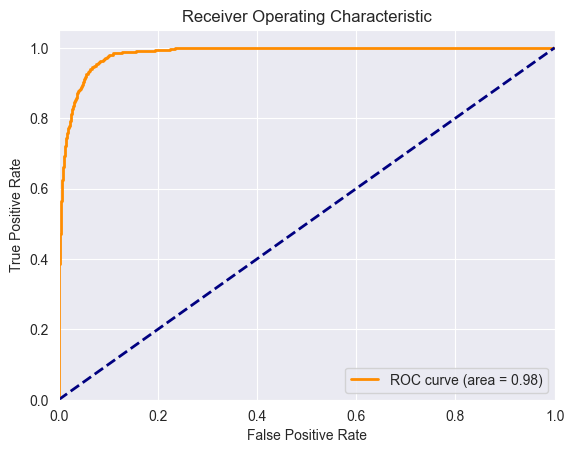

In [ ]:
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % area)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

## Model Evaluation: rank order & KS Statistic

In [ ]:
best_model_logistic.predict_proba(X_test_encoded)[:,1]

df_eval = pd.DataFrame({
    'Default Truth':y_test,
    'Default Probability': probabilities
})

df_eval

,Default Truth,Default Probability
19205,0,0.520
15514,0,0.000
30367,0,0.006
35347,0,0.006
41814,1,0.916
...,...,...
29297,0,0.000
20567,0,0.000
681,0,0.005
33682,0,0.836


In [ ]:
df_eval['Decile'] = pd.qcut(df_eval['Default Probability'], 10, labels=False, duplicates='drop')
df_eval.head()

,Default Truth,Default Probability,Decile
19205,0,0.520,8
15514,0,0.000,2
30367,0,0.006,6
35347,0,0.006,6
41814,1,0.916,9


In [ ]:
df_grouped = df_eval.groupby('Decile').apply(lambda x: pd.Series({
    'Minimum Probability': x['Default Probability'].min(),
    'Maximum Probability': x['Default Probability'].max(),
    'Events': x['Default Truth'].sum(),
    'Non-events': x['Default Truth'].count() - x['Default Truth'].sum(),
}))
df_grouped.reset_index(inplace=True)
df_grouped

,Decile,Minimum Probability,Maximum Probability,Events,Non-events
0,0,0.000,0.000,0.000,1250.000
1,1,0.000,0.000,0.000,1250.000
2,2,0.000,0.000,0.000,1249.000
3,3,0.000,0.000,0.000,1250.000
4,4,0.000,0.001,0.000,1250.000
5,5,0.001,0.004,0.000,1249.000
6,6,0.004,0.028,3.000,1247.000
7,7,0.028,0.213,12.000,1237.000
8,8,0.213,0.819,158.000,1092.000
9,9,0.819,1.000,901.000,349.000


In [ ]:
df_grouped.sort_values('Decile', ascending=False, inplace=True)
df_grouped

,Decile,Minimum Probability,Maximum Probability,Events,Non-events
9,9,0.819,1.000,901.000,349.000
8,8,0.213,0.819,158.000,1092.000
7,7,0.028,0.213,12.000,1237.000
6,6,0.004,0.028,3.000,1247.000
5,5,0.001,0.004,0.000,1249.000
4,4,0.000,0.001,0.000,1250.000
3,3,0.000,0.000,0.000,1250.000
2,2,0.000,0.000,0.000,1249.000
1,1,0.000,0.000,0.000,1250.000
0,0,0.000,0.000,0.000,1250.000


In [ ]:
df_grouped['Event Rate'] = df_grouped['Events']*100 / (df_grouped['Events']+df_grouped['Non-events'])
df_grouped['Non-event Rate'] = df_grouped['Non-events']*100 / (df_grouped['Events']+df_grouped['Non-events'])
df_grouped

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate
9,9,0.819,1.000,901.000,349.000,72.080,27.920
8,8,0.213,0.819,158.000,1092.000,12.640,87.360
7,7,0.028,0.213,12.000,1237.000,0.961,99.039
6,6,0.004,0.028,3.000,1247.000,0.240,99.760
5,5,0.001,0.004,0.000,1249.000,0.000,100.000
4,4,0.000,0.001,0.000,1250.000,0.000,100.000
3,3,0.000,0.000,0.000,1250.000,0.000,100.000
2,2,0.000,0.000,0.000,1249.000,0.000,100.000
1,1,0.000,0.000,0.000,1250.000,0.000,100.000
0,0,0.000,0.000,0.000,1250.000,0.000,100.000


In [ ]:
df_grouped['Cum Events'] =  df_grouped['Events'].cumsum()
df_grouped['Cum Non-events'] =  df_grouped['Non-events'].cumsum()
df_grouped

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events
9,9,0.819,1.000,901.000,349.000,72.080,27.920,901.000,349.000
8,8,0.213,0.819,158.000,1092.000,12.640,87.360,1059.000,1441.000
7,7,0.028,0.213,12.000,1237.000,0.961,99.039,1071.000,2678.000
6,6,0.004,0.028,3.000,1247.000,0.240,99.760,1074.000,3925.000
5,5,0.001,0.004,0.000,1249.000,0.000,100.000,1074.000,5174.000
4,4,0.000,0.001,0.000,1250.000,0.000,100.000,1074.000,6424.000
3,3,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,7674.000
2,2,0.000,0.000,0.000,1249.000,0.000,100.000,1074.000,8923.000
1,1,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,10173.000
0,0,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,11423.000


In [ ]:
df_grouped['Cum Event Rate'] = df_grouped['Cum Events'] * 100 / df_grouped['Events'].sum()
df_grouped['Cum Non-event Rate'] = df_grouped['Cum Non-events']*100 / df_grouped['Non-events'].sum()
df_grouped

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events,Cum Event Rate,Cum Non-event Rate
9,9,0.819,1.000,901.000,349.000,72.080,27.920,901.000,349.000,83.892,3.055
8,8,0.213,0.819,158.000,1092.000,12.640,87.360,1059.000,1441.000,98.603,12.615
7,7,0.028,0.213,12.000,1237.000,0.961,99.039,1071.000,2678.000,99.721,23.444
6,6,0.004,0.028,3.000,1247.000,0.240,99.760,1074.000,3925.000,100.000,34.361
5,5,0.001,0.004,0.000,1249.000,0.000,100.000,1074.000,5174.000,100.000,45.295
4,4,0.000,0.001,0.000,1250.000,0.000,100.000,1074.000,6424.000,100.000,56.237
3,3,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,7674.000,100.000,67.180
2,2,0.000,0.000,0.000,1249.000,0.000,100.000,1074.000,8923.000,100.000,78.114
1,1,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,10173.000,100.000,89.057
0,0,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,11423.000,100.000,100.000


In [ ]:
df_grouped['KS'] = abs(df_grouped['Cum Event Rate'] - df_grouped['Cum Non-event Rate'])
df_grouped

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events,Cum Event Rate,Cum Non-event Rate,KS
9,9,0.819,1.000,901.000,349.000,72.080,27.920,901.000,349.000,83.892,3.055,80.837
8,8,0.213,0.819,158.000,1092.000,12.640,87.360,1059.000,1441.000,98.603,12.615,85.988
7,7,0.028,0.213,12.000,1237.000,0.961,99.039,1071.000,2678.000,99.721,23.444,76.277
6,6,0.004,0.028,3.000,1247.000,0.240,99.760,1074.000,3925.000,100.000,34.361,65.639
5,5,0.001,0.004,0.000,1249.000,0.000,100.000,1074.000,5174.000,100.000,45.295,54.705
4,4,0.000,0.001,0.000,1250.000,0.000,100.000,1074.000,6424.000,100.000,56.237,43.763
3,3,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,7674.000,100.000,67.180,32.820
2,2,0.000,0.000,0.000,1249.000,0.000,100.000,1074.000,8923.000,100.000,78.114,21.886
1,1,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,10173.000,100.000,89.057,10.943
0,0,0.000,0.000,0.000,1250.000,0.000,100.000,1074.000,11423.000,100.000,100.000,0.000


KS ValueThe highest KS value is 85.88%, found at Decile 8. This indicates that the model's performance in distinguishing between events and non-events is most significant at this decile. (If KS is in top 3 decile and score above 40, it is considered a good predictive model.)

In [ ]:
gini_coeff = 2*area -1
print('AUC', area)
print('Gini Coefficient', gini_coeff)

AUC 0.9837803960156833
Gini Coefficient 0.9675607920313667


AUC of 0.98: The model is very good at distinguishing between events and non-events.Gini coefficient of 0.96: This further confirms that the model is highly effective in its predictions, with almost perfect rank ordering capability.The Gini coefficient ranges from -1 to 1, where a value closer to 1 signifies a perfect model, 0 indicates a model with no discriminative power, and -1 signifies a perfectly incorrect model.

<h3 align ='center' style='color:yellow'>Model Finalization</h3>

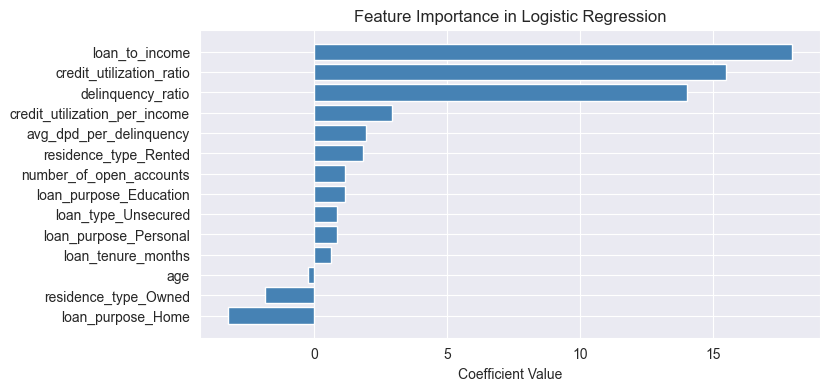

In [ ]:
final_model = best_model_logistic

feature_importance = final_model.coef_[0]

# Create a DataFrame for easier handling
coef_df = pd.DataFrame(feature_importance, index=X_train_encoded.columns, columns=['Coefficients'])

# Sort the coefficients for better visualization
coef_df = coef_df.sort_values(by='Coefficients', ascending=True)

# Plotting
plt.figure(figsize=(8, 4))
plt.barh(coef_df.index, coef_df['Coefficients'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Logistic Regression')
plt.show()

<h3 align ='center' style='color:yellow'>Saving the Model</h3>

In [ ]:
X_test_encoded.head()

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,credit_utilization_per_income,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
19205,0.346,0.755,0.333,0.990,0.550,0.000,0.000,0.127,True,False,False,True,False,False
15514,0.481,0.226,1.000,0.323,0.220,0.000,0.000,0.089,True,False,True,False,False,False
30367,0.231,0.547,0.667,0.828,0.180,0.000,0.000,0.263,True,False,False,False,False,False
35347,0.365,0.755,1.000,0.485,0.571,0.024,0.700,0.060,True,False,False,True,False,False
41814,0.577,0.717,0.667,0.980,0.407,0.107,0.640,0.163,False,False,False,True,False,False


In [ ]:
X_test_encoded.columns

Index(['age', 'loan_tenure_months', 'number_of_open_accounts',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'credit_utilization_per_income',
       'residence_type_Owned', 'residence_type_Rented',
       'loan_purpose_Education', 'loan_purpose_Home', 'loan_purpose_Personal',
       'loan_type_Unsecured'],
      dtype='str')

In [ ]:
cols_to_scale

Index(['age', 'number_of_dependants', 'years_at_current_address',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'credit_utilization_per_income'],
      dtype='str')

In [ ]:
X_train_encoded.columns

Index(['age', 'loan_tenure_months', 'number_of_open_accounts',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'credit_utilization_per_income',
       'residence_type_Owned', 'residence_type_Rented',
       'loan_purpose_Education', 'loan_purpose_Home', 'loan_purpose_Personal',
       'loan_type_Unsecured'],
      dtype='str')

In [ ]:
from joblib import dump

model_data = {
    'model': final_model,
    'features': X_train_encoded.columns,
    'scaler': scaler,
    'cols_to_scale': cols_to_scale
}
dump(model_data, '../info/artifacts/model_data.joblib')

['artifacts/model_data.joblib']

In [ ]:
final_model.coef_, final_model.intercept_

(array([[-0.23787026,  0.64545108,  1.18643785, 15.48577131, 17.96591126,
         14.01397803,  1.96396915,  2.95131088, -1.84807274,  1.84674727,
          1.16772362, -3.22795387,  0.87136537,  0.87136537]]),
 array([-21.2372012]))